# Week 6: Language Models
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%206/Week6_Workshop_Student.ipynb) - nothing to install, everything
runs in your browser. If you opened it in Colab already: great.

Today you meet the three ideas behind every modern language model, one at a
time, each one fixing a problem of the one before:

| Step | Model | What it adds |
|------|-------|--------------|
| 1 | **Word embeddings** | words become numbers that carry meaning |
| 2 | **RNN**, then **LSTM** | reading in order, and remembering what you read |
| 3 | **Transformer** | looking at every word at once, so context decides the meaning |

You do **not** build or train any of these today. You use ready-made models
and look at what they do well, where they break, and who gets hurt when they
break. The spine of the week is the same as in Weeks 4 and 5:
**text -> numbers -> model -> prediction**.

Today runs in **three learning waves**, each starting with a short
mini-lecture. A wave starts at every horizontal line in this notebook,
marked like this:

**LEARNING WAVE 1 · SLIDES 4-8**

- Wave 1 - section 1: words as numbers (embeddings)
- Wave 2 - section 2: order and memory (RNN and LSTM)
- Wave 3 - section 3: context and attention (transformers)
- Then section 4: the big individual assignment, and section 5: wrap-up

Do not run ahead into the next wave - wait for the mini-lecture.

### 0. Setup - run these two cells once

Nothing to write here. Run each cell with Shift + Enter and wait until it
finishes (the first one downloads a 66 MB file, a few seconds). If a cell
prints a long warning about a missing token or about "unauthenticated
requests", ignore it.

In [2]:
# Run, do not read: downloads the pre-trained word embeddings (GloVe, trained by Stanford)
import urllib.request, gzip
import numpy as np
import matplotlib.pyplot as plt

url = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz"
urllib.request.urlretrieve(url, "glove50.gz")

words = []
vectors = []
with gzip.open("glove50.gz", "rt", encoding="utf-8") as f:
    f.readline()                       # first line is just file info
    for i, line in enumerate(f):
        if i >= 50000:                 # keep the 50,000 most common words
            break
        parts = line.rstrip().split(" ")
        words.append(parts[0])
        vectors.append(np.array(parts[1:], dtype="float32"))

V = np.vstack(vectors)
V = V / np.linalg.norm(V, axis=1, keepdims=True)   # length 1, so a dot product = similarity
index = {}
for i, w in enumerate(words):
    index[w] = i
print("Loaded", len(words), "words, each one a list of", V.shape[1], "numbers")

Loaded 50000 words, each one a list of 50 numbers


In [3]:
# Run, do not read: small helper functions that we use all day
def vector(word):
    return V[index[word]]

def similarity(a, b):
    # 1.0 = used in exactly the same way, 0 = nothing in common
    return round(float(vector(a) @ vector(b)), 2)

def neighbours(word, n=8):
    scores = V @ vector(word)
    best = np.argsort(-scores)[1:n + 1]
    return [(words[i], round(float(scores[i]), 2)) for i in best]

def analogy(a, b, c, n=5):
    # "a is to b as c is to ?"   (for example: man is to king as woman is to ?)
    target = vector(b) - vector(a) + vector(c)
    scores = V @ target
    result = []
    for i in np.argsort(-scores):
        if words[i] not in (a, b, c):
            result.append(words[i])
        if len(result) == n:
            break
    return result

def plot_words(word_list):
    # squash the 50 numbers per word into 2, so we can draw a map
    X = np.array([vector(w) for w in word_list])
    X = X - X.mean(axis=0)
    u, s, vt = np.linalg.svd(X, full_matrices=False)
    xy = X @ vt[:2].T
    plt.figure(figsize=(8, 6))
    plt.scatter(xy[:, 0], xy[:, 1])
    for k, w in enumerate(word_list):
        plt.text(xy[k, 0] + 0.02, xy[k, 1] + 0.02, w, fontsize=11)
    plt.title("Words on a map (50 numbers squashed into 2)")
    plt.axis("off")
    plt.show()

---

**LEARNING WAVE 1 · SLIDES 4-8**

## 1. Words as numbers

Sections 1.1 to 1.7. From counting words to giving every word a position on a map of meaning.

### 1.1 What is an embedding?

In slide 5 a sentence became a row of word counts. A count tells you *which*
words appear, but not what they *mean*: to a count, `dog` and `cat` are as
unrelated as `dog` and `car`.

An **embedding** fixes that. Every word gets a list of numbers, and words
that are used in similar ways get similar numbers. The file you just loaded
was trained by Stanford on billions of words. It is **pre-trained**: you do
not train anything today.

Run the cell below. It shows the list of numbers for the word `clinic`.

In [4]:
print(vector("clinic")[:10])
print("This word is a list of", len(vector("clinic")), "numbers. We only printed the first 10.")

[ 0.21052876  0.05483797 -0.15234819 -0.07561343 -0.1071714   0.04723899
 -0.174664    0.03915308  0.24461457 -0.03759914]
This word is a list of 50 numbers. We only printed the first 10.


Your answer: `clinic` is 50 numbers, mostly small values between about -0.2 and 0.2. One number on its own means nothing to me; the meaning is in how close this list is to the lists of other words.

### 1.2 How close are two words?

`similarity(a, b)` compares the two lists of numbers. It gives **1.0** when
two words are used in exactly the same way and values near **0** when they
have nothing in common.

**Predict first.** Which of these five pairs will be the most similar, and
which the least?

- `dog` and `cat`
- `dog` and `car`
- `doctor` and `nurse`
- `clinic` and `hospital`
- `king` and `banana`

Your prediction: most similar `dog`–`cat` (both pets), then `clinic`–`hospital`; least similar `king`–`banana`.

In [5]:
pairs = [("dog", "cat"), ("dog", "car"), ("doctor", "nurse"), ("clinic", "hospital"), ("king", "banana")]
for pair in pairs:
    print(pair[0], "-", pair[1], ":", similarity(pair[0], pair[1]))

dog - cat : 0.92
dog - car : 0.46
doctor - nurse : 0.8
clinic - hospital : 0.86
king - banana : 0.22


Your answer: Almost right. `dog`–`cat` was the highest (0.92), then `clinic`–`hospital` (0.86) and `doctor`–`nurse` (0.80). `king`–`banana` was the lowest (0.22). `dog`–`car` (0.46) is higher than I expected: the words are not similar, but they appear in similar everyday sentences ("my dog", "my car").

### 1.3 The neighbours of a word

`neighbours("clinic")` lists the words closest to `clinic`. Run it, then try
**three words of your own** (lowercase, and a common word, otherwise it may
not be in the list).

In [6]:
print(neighbours("clinic"))

[('hospital', 0.86), ('clinics', 0.82), ('psychiatric', 0.8), ('medical', 0.79), ('nursing', 0.78), ('outpatient', 0.73), ('hospice', 0.73), ('hospitals', 0.72)]


In [7]:
print(neighbours("student"))
print(neighbours("rain"))
print(neighbours("coffee"))


[('teacher', 0.9), ('students', 0.88), ('teachers', 0.86), ('graduate', 0.83), ('school', 0.82), ('teaching', 0.81), ('faculty', 0.8), ('education', 0.8)]
[('rains', 0.88), ('torrential', 0.84), ('winds', 0.83), ('downpour', 0.8), ('snow', 0.79), ('storms', 0.79), ('downpours', 0.78), ('storm', 0.77)]
[('drink', 0.82), ('drinks', 0.82), ('wine', 0.81), ('tea', 0.81), ('beer', 0.8), ('food', 0.79), ('sugar', 0.78), ('corn', 0.76)]


Your answer: The neighbours make sense, but they show *use*, not meaning. `student` is closest to `teacher` (0.90), so words that appear together count as similar even when they are opposites in a classroom. `rain` lists weather words (`torrential`, `downpour`, `snow`). `coffee` lists other drinks (`tea`, `wine`, `beer`), but also `sugar` and `corn`, probably because they appear together in news about crops and prices.

### 1.4 Play Contexto (10 minutes, in the browser)

Open <https://contexto.me/en/> and, together with your neighbour, guess the
word of the day. After every guess the game tells you how *close* your word
is to the secret word. That is exactly the distance you computed above.

Then answer: how did you decide on your next guess?

Your answer: I missed this class, so I did not play it with a neighbour. My strategy would be: start with broad words (a place, an object, a feeling), keep the direction of whichever guess ranks closest, and then try words that are *used in the same kinds of sentences* as that guess. It works like `neighbours`: you move towards the secret word through words that are used alike, not words that look alike.

### 1.5 A map of words

We cannot draw 50 numbers, so the cell below squashes them into 2 and draws a
map. Run it. Which words sit together? Which word is the odd one out?

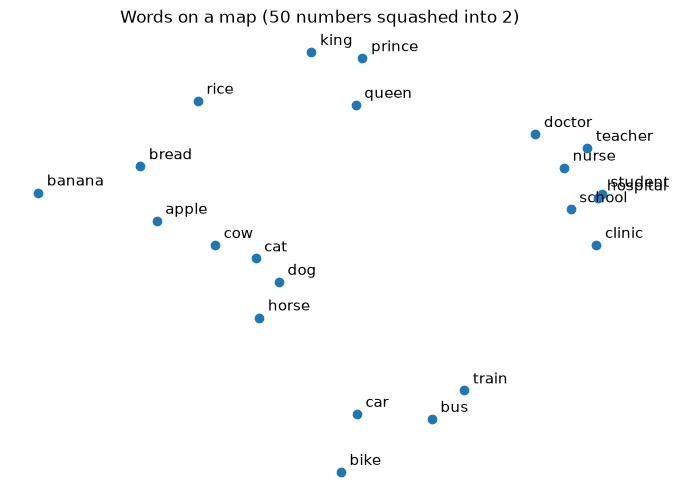

In [8]:
plot_words(["dog", "cat", "horse", "cow", "car", "bus", "train", "bike",
            "doctor", "nurse", "hospital", "clinic", "school", "teacher", "student",
            "king", "queen", "prince", "bread", "rice", "apple", "banana"])

Your answer: The groups are clear: the animals (dog, cat, horse, cow), transport (car, bus, train, bike), royalty (king, prince, with queen a little below), and food (bread, apple, rice, banana) further away on the left. Health and school words (doctor, nurse, clinic, hospital, teacher, school, student) share one cluster, because they are all about institutions and professions. The most isolated word is `banana`, on the far left of the food group.

### 1.6 Arithmetic with meaning

Because words are numbers, you can calculate with them.
`analogy("man", "king", "woman")` answers: *man is to king as woman is to ...?*

Run the first two. Then **predict** what `analogy("man", "doctor", "woman")`
will answer, and run it.

In [9]:
print(analogy("man", "king", "woman"))
print(analogy("paris", "france", "berlin"))

['queen', 'throne', 'prince', 'daughter', 'elizabeth']
['germany', 'denmark', 'poland', 'austria', 'german']


Your prediction: `doctor` (the analogy should keep the job), but I expect `nurse` to show up because of a gender stereotype.

In [10]:
print(analogy("man", "doctor", "woman"))
print(analogy("man", "manager", "woman"))

['nurse', 'child', 'pregnant', 'mother', 'patient']
['assistant', 'owner', 'employee', 'hired', 'executive']


Your answer: The stereotype shows up. "man is to doctor as woman is to …" gave `nurse` first, then `child`, `pregnant` and `mother`, so the "woman" direction pulls towards care and motherhood. (Note: the `analogy` helper leaves out the three input words, so `doctor` itself could never be the answer. The interesting part is *which* words come first instead.) "man is to manager as woman is to …" gave `assistant` first. The embedding did not invent this; it learned it from the texts it was trained on, which is why it is dangerous to use in, for example, CV screening.

### 1.7 One word, one list of numbers

Run the cell below. `bank` has **one** list of numbers, so it has one set of
neighbours.

In [11]:
print(neighbours("bank"))

[('banks', 0.87), ('securities', 0.8), ('banking', 0.8), ('investment', 0.78), ('exchange', 0.78), ('financial', 0.77), ('credit', 0.76), ('lender', 0.75)]


Your answer: All the neighbours of `bank` are about money (`banks`, `securities`, `banking`, `investment`, `lender`). The river meaning does not show up at all. GloVe gives every word one fixed list of numbers, whatever the sentence, so `bank` cannot have a separate river version; money words dominate, probably because the money meaning is more common in its training texts.

---

**LEARNING WAVE 2 · SLIDES 9-14**

## 2. Order and memory: RNN and LSTM

Sections 2.1 to 2.7. Word counts throw away the order of the words. A recurrent network reads the words one by one and carries a memory along. How long can it keep that memory?

### 2.1 Order matters

Bag of words and plain embeddings treat a text as a pile of words. Run the
cell below: it compares the word counts of two sentences with opposite
meanings.

In [12]:
from collections import Counter

good = "the food was good not bad at all"
bad = "the food was bad not good at all"

print(Counter(good.split()))
print(Counter(bad.split()))
print("Same counts?", Counter(good.split()) == Counter(bad.split()))

Counter({'the': 1, 'food': 1, 'was': 1, 'good': 1, 'not': 1, 'bad': 1, 'at': 1, 'all': 1})
Counter({'the': 1, 'food': 1, 'was': 1, 'bad': 1, 'not': 1, 'good': 1, 'at': 1, 'all': 1})
Same counts? True


Your answer: The two sentences mean the opposite, but their word counts are exactly the same ("Same counts? True"). A bag of words cannot tell them apart, because it throws away the order of the words.

### 2.2 Telephone game (in class, 6 minutes, no laptop)

Your teacher will explain the rules. You play two rounds:

1. **The plain chain (the RNN).** A message is whispered down the line. Everyone only knows what the person before them whispered.
2. **The note-taking chain (the LSTM).** Everyone gets a small notebook and may write down one important thing from the message, keep it, and pass it on next to the whisper.

Write down what you notice: what got lost in round 1, and what did the
notebook change in round 2?

Your answer: I missed this in-class game. From the rules: in round 1 (RNN), every person only hears the last whisper, so details from the start of the message get lost or changed bit by bit. In round 2 (LSTM), the notebook keeps the one important thing safe all the way down the line, even when the whisper gets garbled. That is the memory lane of an LSTM.

### 2.3 The memory test

A tiny game to measure memory. Every **sequence** starts with a secret
colour word (red, green, blue or yellow), followed by a number of filler
words. The model reads the whole sequence, word by word, and then has to say
**which colour the sequence started with**.

The only way to win is to remember the first word until the end.

The cell below prepares two tiny models: an **RNN** and an **LSTM**. It also
contains the function `memory_test(kind, length)`, which trains a model for
a few seconds and returns its score on new sequences (1.0 = always right,
0.25 = just guessing). Run it, then look at two examples.

In [13]:
# Run, do not read: two tiny models and a game to test their memory
import torch
import torch.nn as nn

colours = ["red", "green", "blue", "yellow"]
fillers = ["the", "cat", "sat", "on", "a", "mat", "and", "looked", "at", "dog"]

def make_data(n, length, generator):
    first = torch.randint(0, 4, (n,), generator=generator)
    filler = torch.randint(4, 14, (n, length), generator=generator)
    return torch.cat([first.unsqueeze(1), filler], dim=1), first

class TinyReader(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.embedding = nn.Embedding(14, 16)
        if kind == "rnn":
            self.reader = nn.RNN(16, 32, batch_first=True)
        else:
            self.reader = nn.LSTM(16, 32, batch_first=True)
            for name, p in self.reader.named_parameters():
                if "bias" in name:
                    p.data[32:64] = 1.0     # start with 'keep what you remember'
        self.answer = nn.Linear(32, 4)

    def forward(self, x):
        out, _ = self.reader(self.embedding(x))
        return self.answer(out[:, -1, :])    # the answer comes after the LAST word

def memory_test(kind, length, seed=1):
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    x_train, y_train = make_data(2000, length, g)
    x_test, y_test = make_data(1000, length, g)
    net = TinyReader(kind)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
    loss_function = nn.CrossEntropyLoss()
    for epoch in range(30):
        order = torch.randperm(2000)
        for i in range(0, 2000, 100):
            batch = order[i:i + 100]
            optimizer.zero_grad()
            loss_function(net(x_train[batch]), y_train[batch]).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            optimizer.step()
    with torch.no_grad():
        return round((net(x_test).argmax(1) == y_test).float().mean().item(), 2)

def show_example(length):
    g = torch.Generator().manual_seed(length)
    x, y = make_data(1, length, g)
    tokens = x[0].tolist()
    print(colours[tokens[0]], " ".join(fillers[t - 4] for t in tokens[1:]))
    print("-> the model must answer:", colours[int(y[0])])
    print()

In [14]:
show_example(5)
show_example(15)

yellow a looked mat and the
-> the model must answer: yellow

red dog the on looked a a cat dog dog on the looked on dog mat
-> the model must answer: red



**Predict first.** We test sequences with 5, 10, 20 and 30 filler words
after the colour. For each length, will the model still remember the
colour? Write your guess for the RNN and for the LSTM.

Your prediction: RNN: fine at 5 and 10, worse at 20, guessing at 30. LSTM: right at 5, 10 and 20, maybe a bit worse at 30.

### 2.4 Test the RNN

This trains a fresh RNN for each length (about 5 seconds each) and prints
the score.

In [15]:
lengths = [5, 10, 20, 30]
rnn_scores = []
for length in lengths:
    score = memory_test("rnn", length)
    rnn_scores.append(score)
    print("RNN, after", length, "filler words ->", score)

RNN, after 5 filler words -> 1.0


RNN, after 10 filler words -> 1.0


RNN, after 20 filler words -> 0.48


RNN, after 30 filler words -> 0.25


### 2.5 Test the LSTM

Exactly the same game, with the LSTM instead.

In [16]:
lstm_scores = []
for length in lengths:
    score = memory_test("lstm", length)
    lstm_scores.append(score)
    print("LSTM, after", length, "filler words ->", score)

LSTM, after 5 filler words -> 1.0


LSTM, after 10 filler words -> 1.0


LSTM, after 20 filler words -> 1.0


LSTM, after 30 filler words -> 1.0


### 2.6 Compare

Run the cell below to draw both results in one picture, then answer.

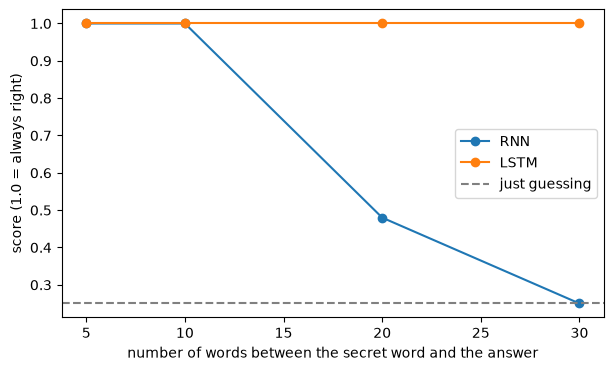

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(lengths, rnn_scores, marker="o", label="RNN")
plt.plot(lengths, lstm_scores, marker="o", label="LSTM")
plt.axhline(0.25, color="grey", linestyle="--", label="just guessing")
plt.xlabel("number of words between the secret word and the answer")
plt.ylabel("score (1.0 = always right)")
plt.legend()
plt.show()

Your answer: The RNN is perfect at 5 and 10 filler words, drops to 0.48 at 20 and is just guessing at 30 (0.25): the colour fades from its memory. The LSTM stays at 1.0 for every length up to 30, because its memory lane carries the colour past all the filler words. My prediction was right for the RNN; the LSTM did even better than I expected.

### 2.7 Your turn: push the LSTM

Test the LSTM on a much longer sequence, for example 50 filler words. Use
`memory_test("lstm", 50)` and print the result. Do it a second time with
`seed=2` as an extra argument (`memory_test("lstm", 50, seed=2)`).

In [18]:
print("LSTM, 50 filler words (seed 1):", memory_test("lstm", 50))
print("LSTM, 50 filler words (seed 2):", memory_test("lstm", 50, seed=2))


LSTM, 50 filler words (seed 1): 0.74


LSTM, 50 filler words (seed 2): 0.74


Your answer: At 50 filler words the LSTM is no longer perfect: 0.74 with seed 1 and also 0.74 with seed 2. It still remembers much better than guessing (0.25), but long texts are hard even for an LSTM, which is the problem transformers solve.

---

**LEARNING WAVE 3 · SLIDES 15-20**

## 3. Context and attention: transformers

Sections 3.1 to 3.7. A transformer does not read one word at a time: every word looks at every other word at once. We use two small pre-trained transformers.

### 3.0 Load the transformers

Run this cell once. It downloads two small pre-trained models:
**DistilBERT**, which has been taught to read English (and, in a second
version, to judge whether a text is positive or negative), and **DistilGPT-2**, which has been taught to predict the next
word. This takes up to a minute. Ignore warnings about tokens.

In [19]:
# Run, do not read: loads two small pre-trained transformers
from transformers import pipeline, AutoModel, AutoModelForCausalLM, AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
sentiment = pipeline("sentiment-analysis", model=checkpoint)
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
encoder = AutoModel.from_pretrained("distilbert-base-uncased").eval()

lm_tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
lm = AutoModelForCausalLM.from_pretrained("distilgpt2").eval()

def show(sentences):
    for result, sentence in zip(sentiment(sentences), sentences):
        print(result["label"], round(result["score"], 2), "|", sentence)

def word_vector(sentence, word):
    # the list of numbers for ONE word, as this model sees it IN THIS sentence
    enc = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = encoder(**enc).last_hidden_state[0]
    position = enc["input_ids"][0].tolist().index(tokenizer.convert_tokens_to_ids(word))
    v = hidden[position]
    return v / v.norm()

def context_similarity(sentence_1, sentence_2, word="bank"):
    return round(float(word_vector(sentence_1, word) @ word_vector(sentence_2, word)), 2)

def next_words(prompt, n=6):
    ids = lm_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        logits = lm(**ids).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, n)
    for p, i in zip(top.values, top.indices):
        print(round(float(p), 3), "|", lm_tokenizer.decode(int(i)))

def write(prompt, temperature=1.0, length=25, seed=1):
    torch.manual_seed(seed)
    ids = lm_tokenizer(prompt, return_tensors="pt")
    out = lm.generate(**ids, max_new_tokens=length, do_sample=True,
                      temperature=temperature, pad_token_id=lm_tokenizer.eos_token_id)
    print(lm_tokenizer.decode(out[0]).replace("\n", " "))

def pronoun_odds(prompt):
    ids = lm_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(lm(**ids).logits[0, -1], dim=-1)
    she = float(probs[lm_tokenizer.encode(" she")[0]])
    he = float(probs[lm_tokenizer.encode(" he")[0]])
    print(prompt, "| she:", round(she, 3), "| he:", round(he, 3))

### 3.1 One word, many meanings

In 1.7 `bank` had one list of numbers, always. A transformer gives a word a
**different list of numbers in every sentence**, because it looks at the
other words first.

`context_similarity(sentence_1, sentence_2)` compares the lists of numbers
of the word `bank` in two sentences. **Predict first:** which comparison
will be the *highest* and which the *lowest*?

- A: `she sat on the bank of the river`
- B: `he deposited money at the bank`
- C: `the bank approved the loan`
- D: `we had a picnic on the river bank`

Your prediction: highest A–D (both river) and B–C (both money); lowest one of the river–money pairs.

In [20]:
A = "she sat on the bank of the river"
B = "he deposited money at the bank"
C = "the bank approved the loan"
D = "we had a picnic on the river bank"

print("A and D (both river):", context_similarity(A, D))
print("B and C (both money):", context_similarity(B, C))
print("A and B (river / money):", context_similarity(A, B))
print("D and C (river / money):", context_similarity(D, C))

A and D (both river): 0.78
B and C (both money): 0.78
A and B (river / money): 0.56
D and C (river / money): 0.54


Your answer: Correct. A–D (both river) and B–C (both money) are both 0.78, while the river/money pairs are lower (0.56 and 0.54). So the transformer gives `bank` a different list of numbers depending on the other words in the sentence, unlike GloVe in 1.7, where `bank` was always about money.

### 3.2 Be attention (in class, 6 minutes)

Your teacher shows a sentence on screen: *The animal didn't cross the street
because it was too tired.* Every student is one word. The student who is `it`
points at the words they need to look at to know what `it` means, and the
rest of the class checks.

Then the teacher changes the end of the sentence to *... because it was too
wide.* Who does `it` look at now?

Write down: which words did `it` look at, and what changed?

Your answer: I missed this in-class activity. With "because it was too tired", `it` has to look at `animal`, because an animal can be tired and a street cannot. With "because it was too wide", `it` looks at `street`. Only the last word changed, but it changes which word `it` pays attention to. That is what attention does in a transformer.

### 3.3 Sentiment: where does it fail?

`show([...])` gives you the model's verdict (POSITIVE or NEGATIVE) and how
sure it is (0 to 1) for a list of sentences. Look at the sentences below and
**predict** which ones the model will get wrong.

Your prediction: it will get wrong the double negative ("wouldn't say … unfriendly"), the sarcastic one ("Great, another two-hour wait"), the typo sentence and the Dutch sentence.

In [21]:
show(["The clinic helped me a lot.",
      "The clinic did not help me at all.",
      "I wouldn't say the staff were unfriendly.",
      "Great, another two-hour wait. Just what I needed.",
      "The doctor was kind, but the waiting room was awful.",
      "the cluic wuz rly good",
      "Het was een heel goede ervaring."])

POSITIVE 1.0 | The clinic helped me a lot.
NEGATIVE 1.0 | The clinic did not help me at all.
NEGATIVE 0.97 | I wouldn't say the staff were unfriendly.
POSITIVE 0.99 | Great, another two-hour wait. Just what I needed.
NEGATIVE 1.0 | The doctor was kind, but the waiting room was awful.
POSITIVE 1.0 | the cluic wuz rly good
NEGATIVE 0.97 | Het was een heel goede ervaring.


Your answer: It got three wrong, all of them very confidently: the double negative ("I wouldn't say the staff were unfriendly", NEGATIVE 0.97), the sarcasm ("Great, another two-hour wait", POSITIVE 0.99), and the Dutch sentence ("Het was een heel goede ervaring" means "It was a very good experience", NEGATIVE 0.97). The typo sentence ("the cluic wuz rly good") was correct, which surprised me. The confidence number does not tell you when the model is wrong.

Now try **three sentences of your own** that you think will fool the
model. Use `show(["sentence one", "sentence two", "sentence three"])`.

In [22]:
show(["Oh perfect, my appointment got cancelled again.",
      "It's not that the counsellor was bad, I just didn't feel heard.",
      "The advice was sick, honestly saved my semester."])


NEGATIVE 1.0 | Oh perfect, my appointment got cancelled again.
NEGATIVE 1.0 | It's not that the counsellor was bad, I just didn't feel heard.
NEGATIVE 0.59 | The advice was sick, honestly saved my semester.


Your answer: Only one of my three fooled it. It understood the sarcastic "Oh perfect, my appointment got cancelled again" (NEGATIVE 1.0), and "not that the counsellor was bad, I just didn't feel heard" is negative, so it was right there too. But slang fooled it: "The advice was sick, honestly saved my semester" is very positive, and the model said NEGATIVE, though with low confidence (0.59). Probably it reads "sick" in its old, negative meaning.

### 3.4 What an LLM does: guess the next word

ChatGPT, Claude and Gemini are transformers trained to do one thing:
**predict the next word**. `next_words(prompt)` shows the six most likely
next words (with their probability) according to DistilGPT-2, a small
relative. Run it, then try your own prompt.

In [23]:
next_words("The doctor said that")

0.174 |  he
0.159 |  the
0.044 |  she
0.042 |  it
0.036 |  his
0.026 |  if


In [24]:
next_words("Students who ask for help are")


0.153 |  asked
0.039 |  being
0.039 |  encouraged
0.039 |  not
0.03 |  given
0.028 |  invited


Your answer: For "The doctor said that", the most likely next word is `he` (0.174), much more likely than `she` (0.044): the model assumes the doctor is a man. For my own prompt, "Students who ask for help are", the top word is `asked` (0.15), then `being`, `encouraged` and `not`. The options are fairly neutral, but it only predicts what usually follows in internet texts; it does not know anything about the students.

### 3.5 Temperature

`write(prompt, temperature=...)` lets the model keep adding words. The
**temperature** sets how adventurous it is: low = always take the most likely
next word, high = sometimes pick an unlikely one. Run both and compare.

In [25]:
write("The doctor said that", temperature=0.3)
print()
write("The doctor said that", temperature=1.5)

The doctor said that the patient was not in the hospital for the first time in the past two weeks.        



The doctor said that after receiving 10 days of intensive treatment for multiple sclerosis, I was about to fall behind the rate in my primary care system but


Your answer: At temperature 0.3 the text is calm and sensible ("…the patient was not in the hospital for the first time in the past two weeks."). At 1.5 it gets adventurous and stops making sense: it switches to "I", jumps to multiple sclerosis and "primary care system", and does not finish the sentence. Low temperature = less varied (it sticks to the most likely words); high = more varied and, here, much less coherent. A likely sentence is not automatically a true one. (Both texts stop after 25 new tokens, so the unfinished ending is the length limit, not the temperature.)

### 3.6 What did it learn from the internet?

A language model learned from texts written by people. The cell below asks
the model how likely the next word is **she** or **he** after four different
jobs.

In [26]:
pronoun_odds("The nurse said that")
pronoun_odds("The engineer said that")
pronoun_odds("The doctor said that")
pronoun_odds("The teacher said that")

The nurse said that | she: 0.224 | he: 0.032
The engineer said that | she: 0.011 | he: 0.109
The doctor said that | she: 0.044 | he: 0.174
The teacher said that | she: 0.162 | he: 0.147


Your answer: The model follows job stereotypes. After "The nurse said that" it expects `she` (0.22) much more than `he` (0.03). After "engineer" (he 0.11 vs she 0.01) and "doctor" (he 0.17 vs she 0.04) it expects `he`. "Teacher" is almost balanced (she 0.16, he 0.15). It learned this from texts written by people, so it repeats our stereotypes back to us.

### 3.7 Who is misread?

You saw three kinds of failure today: a stereotype in the embedding (1.6),
a sarcastic sentence (3.3) and a Dutch sentence (3.3). Imagine a clinic's
helpline that uses a language model to sort incoming messages into *urgent*
and *not urgent*.

Which people would be misread most often, and what would a responsible
clinic do about it?

Your answer: People who write differently from the English internet text the model learned from: people writing in Dutch or another language, or in simple or broken English (many migrants and international students), people who use sarcasm or slang, and people who describe a serious problem politely or with a double negative. Their urgent message could be sorted as "not urgent". A responsible clinic would test the model on real messages from all of these groups first, never let it make the final decision, have a human read everything it marks "not urgent", support other languages, and tell users that a person reads their message.

---

## 4. Big individual assignment: stress-test a language model

**You are a tester, not a builder.** An organisation wants to use the
sentiment model from section 3 to read feedback from its users. Before it
does, it asks you: **where does this model fail, and who would that hurt?**

Pick a context you care about (a clinic, a food bank, a housing association,
a school, a municipality ...). You work with the pre-trained model `sentiment`
and the `show` function from section 3.

**Required skills and outputs**

1. **A test set of at least 12 sentences** about your context, covering at
   least four of these kinds: negation, mixed feelings, sarcasm or irony,
   a long sentence where the key word is far from the end, typos or slang,
   a sentence in another language (for example Dutch).
2. **Your own label first.** Before running anything, write down for each
   sentence what a person would say (positive or negative).
3. **Run the model** and collect the results in a table (a pandas
   DataFrame): sentence, your label, the model's label, its confidence, and
   whether they agree.
4. **Error analysis.** Which kinds of sentences fail? For three failures, say
   what a reader would have needed to get it right (the order of the words,
   a memory of an earlier word, the context around a word) and which step of
   today's ladder (embedding, RNN, LSTM, transformer) would or would not
   have handled it, and why.
5. **A bias probe.** Use `next_words` or `pronoun_odds` with at least two
   prompts that differ in one word (for example two jobs, two names or two
   nationalities) and describe what changes.
6. **A written judgement** (about 150 words): would you let this model read
   the users' feedback? Under which conditions? Who is misread, and what
   does the organisation do about them?

**Bonus options**

- Run your test set through a second model from <https://huggingface.co/models>
  (search for a multilingual sentiment model) by creating a second
  `pipeline("sentiment-analysis", model="...")`, and compare the table.
- Try three different temperatures with `write` for one story prompt and
  describe how the text changes.
- Find a biased analogy in the embeddings of section 1 with `analogy`.

You are graded on the honesty of your error analysis and on your reasoning
about harm, not on how many sentences the model gets right.

In [27]:
# 1. Context I chose:
# The student-support service of a university (study advisors, counsellors, the wellbeing desk).
# The university wants the sentiment model to sort feedback forms, so staff read the negative ones first.
# Many students are international, so feedback comes in English, Dutch and other languages.
import pandas as pd

# 2. My test sentences and my own labels (written BEFORE running the model)
tests = [
    ("The study advisor really listened and helped me plan my resit.", "POSITIVE", "plain"),
    ("I did not feel supported at all.", "NEGATIVE", "negation"),
    ("I wouldn't say the counsellor was unhelpful.", "POSITIVE", "negation"),
    ("Not bad, actually.", "POSITIVE", "negation"),
    ("The counsellor was kind, but I waited three weeks for an appointment.", "NEGATIVE", "mixed"),
    ("The waiting list is terrible, but the session itself changed a lot for me.", "POSITIVE", "mixed"),
    ("Wow, a reply after only five weeks. Amazing service.", "NEGATIVE", "sarcasm"),
    ("Great, the only workshop on exam stress is during my exam.", "NEGATIVE", "sarcasm"),
    ("After filling in three forms, sending two emails, and explaining my situation to four different people, I finally got exactly the help I needed.", "POSITIVE", "long"),
    ("Everyone at the desk smiled, the room was nice and the coffee was free, but nobody could answer my question.", "NEGATIVE", "long"),
    ("the advisr was rly helpfull tbh", "POSITIVE", "typos/slang"),
    ("ngl the wellbeing desk is lowkey a lifesaver", "POSITIVE", "typos/slang"),
    ("De studieadviseur heeft me heel goed geholpen.", "POSITIVE", "other language"),
    ("Nagyon rossz élmény volt, senki nem segített.", "NEGATIVE", "other language"),
]

# 3. Run the model, build the table (pandas DataFrame)
results = sentiment([sentence for sentence, label, kind in tests])
table = pd.DataFrame({
    "kind": [kind for sentence, label, kind in tests],
    "sentence": [sentence for sentence, label, kind in tests],
    "my label": [label for sentence, label, kind in tests],
    "model label": [r["label"] for r in results],
    "confidence": [round(r["score"], 3) for r in results],
})
table["agree"] = table["my label"] == table["model label"]
pd.set_option("display.max_colwidth", 70)
print("Model agreed with me on", table["agree"].sum(), "of", len(table), "sentences")
print()
print("Agreement per kind of sentence:")
print(table.groupby("kind")["agree"].agg(["sum", "count"]))
table

# 4. Which sentences failed? Why? Which rung of the ladder would have handled them?
#    -> see the markdown cell "Error analysis" below (written after looking at this table).


Model agreed with me on 8 of 14 sentences

Agreement per kind of sentence:
                sum  count
kind                      
long              2      2
mixed             1      2
negation          2      3
other language    1      2
plain             1      1
sarcasm           1      2
typos/slang       0      2


,kind,sentence,my label,model label,confidence,agree
0,plain,The study advisor really listened and helped me plan my resit.,POSITIVE,POSITIVE,0.997,True
1,negation,I did not feel supported at all.,NEGATIVE,NEGATIVE,1.000,True
2,negation,I wouldn't say the counsellor was unhelpful.,POSITIVE,NEGATIVE,0.996,False
3,negation,"Not bad, actually.",POSITIVE,POSITIVE,0.999,True
4,mixed,"The counsellor was kind, but I waited three weeks for an appointment.",NEGATIVE,NEGATIVE,0.996,True
5,mixed,"The waiting list is terrible, but the session itself changed a lot...",POSITIVE,NEGATIVE,0.793,False
6,sarcasm,"Wow, a reply after only five weeks. Amazing service.",NEGATIVE,POSITIVE,0.999,False
7,sarcasm,"Great, the only workshop on exam stress is during my exam.",NEGATIVE,NEGATIVE,0.953,True
8,long,"After filling in three forms, sending two emails, and explaining m...",POSITIVE,POSITIVE,0.997,True
9,long,"Everyone at the desk smiled, the room was nice and the coffee was ...",NEGATIVE,NEGATIVE,0.999,True


In [28]:
# 5. Bias probe (two prompts that differ in one word)
pronoun_odds("The student who failed the exam said that")
pronoun_odds("The student who passed the exam said that")
next_words("The Dutch student was")
next_words("The Hungarian student was")


The student who failed the exam said that | she: 0.211 | he: 0.264
The student who passed the exam said that | she: 0.241 | he: 0.289
0.125 |  arrested
0.036 |  shot
0.034 |  killed
0.024 |  found
0.019 |  attacked
0.019 |  detained
0.126 |  arrested
0.041 |  shot
0.04 |  killed
0.023 |  detained
0.021 |  found
0.019 |  attacked


Your answer:

#### Error analysis
The model agreed with my own label on **8 of 14** sentences. Everything plain or clearly worded was right. Typos and slang failed **2 of 2**, the Dutch sentence failed, and so did one sarcastic, one mixed and one double-negative sentence. It never sounded unsure: most wrong answers had a confidence above 0.97.

Three failures:
1. **"I wouldn't say the counsellor was unhelpful."** (my label positive, model NEGATIVE 0.996). A reader needs to combine *wouldn't* and *un-helpful*: two negatives that cancel out. A bag of words or a single embedding only sees the negative words. An RNN/LSTM reads in order but still has to learn this rare pattern. A transformer can link the two words with attention, but it also has to have learned what the combination means; this model did not get it right.
2. **"Wow, a reply after only five weeks. Amazing service."** (negative, model POSITIVE 0.999). You need the context: five weeks is a long wait, so "amazing" is sarcastic. The architecture alone does not tell a model that five weeks is too long; that is knowledge about the world. A transformer trained on enough texts about waiting times could pick it up, but this small sentiment model did not.
3. **"De studieadviseur heeft me heel goed geholpen."** ("The study advisor helped me very well", model NEGATIVE 0.977). This model was trained on English texts only (English books and Wikipedia, then English movie reviews), so it has no reliable understanding of Dutch, even though it can split Dutch words into pieces. No rung of the ladder helps if the training data does not contain the language; you need a multilingual model. The Hungarian negative sentence was right, but probably by luck, with lower confidence (0.86).

#### Bias probe
"The student who failed the exam said that" vs "… passed …": `she` and `he` change almost the same way (she 0.21 → 0.24, he 0.26 → 0.29), so I found no gender difference here, only a small general lean towards `he`. "The Dutch student was" vs "The Hungarian student was": both get `arrested` as the most likely next word (0.125 and 0.126), then `shot` and `killed`. So the nationality did not change much, but the model expects crime after "[nationality] student was", probably because news texts use that pattern for crime stories.

#### Written judgement
I would not let this model sort the student-support feedback on its own. It was right on clear English sentences, but wrong on the Dutch sentence, on both slang sentences, and on polite, mixed or sarcastic feedback about a long wait. It got the one Hungarian sentence right, but one sentence proves nothing. These are often exactly the students who most need to be heard: international students and students who write informally. Worse, five of its six mistakes had a confidence between 97.7% and 99.9%, so staff would trust its mistakes. If the university uses it, then only as a helper: a person still reads every message, and the model only suggests an order. Before using it, test it on a few hundred real feedback forms, compare the results per language, and switch to a multilingual model. Tell students that a person reads their feedback, and check the errors again every few months.

---

## 5. Wrap-up

### 5.1 The ladder

Each step fixed a weakness of the one before:

| Model | What it does well | What it still cannot do |
|-------|-------------------|-------------------------|
| Bag of words | counts which words occur, simple and fast | no order, no meaning |
| **Word embeddings** | words that are used alike get similar numbers | one fixed meaning per word, no order |
| **RNN** | reads in order, any length | forgets the beginning of long texts |
| **LSTM** | keeps what matters in a memory lane | reads one word at a time, slow, long texts still hard |
| **Transformer** | every word looks at every other word at once, meaning depends on the context | needs huge data and computers; copies the bias of its data |

### 5.2 Five things to remember

1. A computer does not read. It turns text into numbers and calculates.
2. Embeddings give every word a place on a map of meaning, so similar words end up close.
3. Order matters. An RNN reads in order but forgets; an LSTM remembers longer.
4. A transformer lets every word look at every other word. That is why context finally works, and it is the foundation of ChatGPT, Claude and Gemini.
5. All of these models copy the data they learned from. They sound sure even when they are wrong, so keep a human in the loop and ask who is misread.

### 5.3 Homework (while you work on the hackathon)

Complete these DataCamp chapters:

1. *Recurrent Neural Networks (RNN) for Language Modeling with Keras*: **Chapter 1** and **Chapter 4**
   <https://app.datacamp.com/learn/courses/recurrent-neural-networks-rnn-for-language-modeling-with-keras>
2. *Introduction to LLMs in Python*: the whole chapter **Getting started with Large Language Models (LLMs)**
   <https://campus.datacamp.com/courses/introduction-to-llms-in-python/getting-started-with-large-language-models-llms>

Also finish section 4 and upload the notebook to `Term 1/Week 6/homework/` in your portfolio.

**Next week:** Computer Vision
**Friday:** the hackathon. You find out on the day which tool you use and which problem you solve.